In [ ]:
import os
import sys
import joblib

import numpy as np
import pandas as pd
import scipy.stats as stats

sys.path.insert(0, '../../..') 
from utils.helper_functions import normalize_series
from utils.metrics import movement_level_confusion
from utils.constants import Configs
from utils.helper_functions import load_outlier_data
from utils.plotting import plot_movement_data
from utils.loso_models.zscore_detector import ZScoreDetector
from utils.helper_functions import calculate_matrix_trash_percentage
from utils.loso_pipeline import run_loso_evaluation
from utils.helper_functions import save_loso_results
from utils.helper_functions import append_experiment_record
from utils.bootstrap_utils import compute_bootstrap_ci_all_levels
from utils.dtw_radius import load_dtw_matrices

TARGET_MOVEMENT = 'Pick'
ALGORITHM_NAME = 'ZScore'
MODEL_REPRESENTATION = 'ShapeBased'

EXTRACT_SCORES = True

/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/hugo-guimar-es/Documents/GitHub/python_zeromq/Outlier_Removal/.venv/lib/python3.13/site-packages/tslearn/bases/bases.py:16: UserWarning: h5py not installed, hdf5 features will not be supported.
Install h5py to use hdf5 features: http://docs.h5py.org/
  warn(h5py_msg)


In [2]:
# Load the processed data from the csv
cache_path = Configs.SMART_RETAIL_FILTERED_DATA_BIMANUAL
if not os.path.exists(cache_path):
    raise FileNotFoundError(f"Processed data not found at {cache_path}. Please run the data processing notebook first.")

df = pd.read_csv(cache_path)
df = df.sort_values(by=Configs.KEYS + ['step']).reset_index(drop=True)
df_filtered = df[df['movLabel'] == TARGET_MOVEMENT].copy()

In [3]:
# Metadata: one line per movement, same order as the matrices
results_temp_base = df_filtered[Configs.KEYS].drop_duplicates().reset_index(drop=True)
n_movements = len(results_temp_base)

In [4]:
print("\n--- Fusing Outliers into a singular Ground Truth ---")

# Load the known outliers from the csv
outliers_left_csv, _  = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_LEFT_PATH)
outliers_right_csv, _ = load_outlier_data(Configs.SMART_RETAIL_OUTLIERS_RIGHT_PATH)

def prep_gt(gt, phase):
    """
    Prepare the ground truth data for a specific phase.
    """
    gt = gt[gt['movLabel'] == phase] if 'movLabel' in gt.columns else gt
    return gt.drop_duplicates(subset=Configs.KEYS).reset_index(drop=True)

gt_left  = prep_gt(outliers_left_csv,  TARGET_MOVEMENT)
gt_right = prep_gt(outliers_right_csv, TARGET_MOVEMENT)
gt_union = (pd.concat([gt_left, gt_right])
              .drop_duplicates(subset=Configs.KEYS).reset_index(drop=True))

GT = {'L': gt_left, 'R': gt_right, 'OR': gt_union}
for k, g in GT.items():
    print(f"GT {k}: {len(g)} positivos / {n_movements} movimentos = {len(g)/n_movements*100:.2f}%")

# All positive samples must exist in the metadata
base_keys = set(map(tuple, results_temp_base[Configs.KEYS].values))
for k, g in GT.items():
    missing = [t for t in map(tuple, g[Configs.KEYS].values) if t not in base_keys]
    assert not missing, f"GT {k}: {len(missing)} positivos sem movimento correspondente"


--- Fusing Outliers into a singular Ground Truth ---
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_left.csv
Loading outlier data from /home/hugo-guimar-es/Documents/GitHub/python_zeromq/Data/SmartRetail/outliers/outliers_right.csv
GT L: 2 positivos / 380 movimentos = 0.53%
GT R: 2 positivos / 380 movimentos = 0.53%
GT OR: 3 positivos / 380 movimentos = 0.79%


In [5]:
# group_array = [
#     'xs_L', 'ys_L', 'zs_L', 'xe_L', 'ye_L', 'ze_L', 'xw_L', 'yw_L', 'zw_L', # Braço Esquerdo
#     'xs_R', 'ys_R', 'zs_R', 'xe_R', 'ye_R', 'ze_R', 'xw_R', 'yw_R', 'zw_R'  # Braço Direito
# ]
group_array = [
    'x_L', 'y_L', 'z_L', # Left Arm
    'x_R', 'y_R', 'z_R' # Right Arm
]
sample_size = None

X_movement = normalize_series(
        df_input=df,
        movLabel_filter=TARGET_MOVEMENT,
        useScaler=False,
        group_array=group_array,
        sample_size=sample_size
)  # shape (n_samples, T, 18)

Processing time series: 100%|██████████| 380/380 [00:00<00:00, 2785.04it/s]

Shape of first series: (106, 6)


Shape of formatted series: (380, 461, 6)


In [ ]:
# =========================================================================
# Base vars for future calculations 
# =========================================================================

n_positives = {k: len(g) for k, g in GT.items()}

def get_base_vars(gt_key: str) -> tuple:
    gt_used = GT[gt_key]

    # Ground truth used for evalution on this run
    total_known_outliers = len(gt_used)

    # Movement-level anomalies
    known_outlier_rate = total_known_outliers / n_movements if n_movements > 0 else 0.0
    known_percentage = known_outlier_rate * 100
    
    # print(f"GT used ({"Union"}): {total_known_outliers} positives / {n_movements} movements = {known_percentage:.2f}%")
    return gt_used, total_known_outliers, known_percentage


# Sincronization: series matrix (X_movement) and DTW matrix must have the same number of rows as the metadata
if X_movement.shape[0] != n_movements:
    raise ValueError(f"X_movement ({X_movement.shape[0]}) != metadata ({n_movements})")
# if dtw_matrix.shape[0] != n_movements:
    # raise ValueError(f"DTW ({dtw_matrix.shape[0]}) != metadata ({n_movements})")


# print(f"✅ Sincronization OK. Lines: X={X_movement.shape[0]} | DTW={dtw_matrix.shape[0]} | metadata={n_movements}")
print(f"Phase: {TARGET_MOVEMENT}")
print(f"positives by ground truth: {n_positives}")

Phase: Pick
positives by ground truth: {'L': 2, 'R': 2, 'OR': 3}
GT used (Union): 3 positives / 380 movements = 0.79%


## Z-Score

### Normality Test
I cannot just simply throw a shapiro test hoping that will work. That test has a maximum ammount of features it can support, so, I will reduce the N x N matrix to a 1D array with N lenght, that, every cell has the mean of each line of the matrix. And with that array I will do a shapiro test.

In [7]:
# mean_distances = np.mean(dtw_matrix, axis=1)

# stat, p_value = stats.shapiro(mean_distances)

# print("--- Shapiro-Wilk Test Results ---")
# print("---------------------------------")
# print(f"{'Feature':<15} | {'P-Value':<12} | {'Conclusion'}")
# is_normal = p_value > 0.05
# conclusion = "Normal" if is_normal else "Not Normal"
# print(f"{'Mean Distance':<15} | {p_value:.6f} | {conclusion}")


## Z-Score DTW

### Grid Search

In [ ]:
print("\n--- Starting LOSO Baseline: Z-Score (DTW) ---")

Z_THRESHOLDS = [0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.75, 2.0, 2.5, 3.0]
param_grid_z = [{'z_threshold': z} for z in Z_THRESHOLDS]

matrices = load_dtw_matrices(TARGET_MOVEMENT, Configs.DTW_RADIUS_Seconds, Configs.late_fusion_dtw_matrix_path)

for exp in Configs.EXPERIMENTS:
    print(f"\n\n--- Running experiment: {exp.exp_id} ---")

    gt_used, total_known_outliers, known_percentage = get_base_vars(exp.gt_key)

    loso_results = run_loso_evaluation(
        detector_class=ZScoreDetector, 
        param_grid=param_grid_z,
        data_matrix=matrices[0.5], # TODO placeholder, replaced per fold TODO
        metadata_df=results_temp_base,
        known_outliers_df=gt_used,
        metric_type='precomputed',
        compute_trial_level=False,
        extract_scores=EXTRACT_SCORES,
        print_results=False,
        dtw_matrices=matrices
    )

    save_loso_results(
        model_name=ALGORITHM_NAME,
        representation=MODEL_REPRESENTATION,
        experiment_name=exp.exp_id,
        target_movement=TARGET_MOVEMENT,
        loso_results=loso_results,
    )

    ci_results = compute_bootstrap_ci_all_levels(loso_results, compute_scores=EXTRACT_SCORES, seed=42)

    append_experiment_record(
        summary_path=Configs.loso_model_summary_path(MODEL_REPRESENTATION, exp.gt_key),
        phase=TARGET_MOVEMENT,
        representation=MODEL_REPRESENTATION,
        algorithm=ALGORITHM_NAME,
        total_samples=n_movements,
        loso_results=loso_results,
        bootstrap_results=ci_results,
    )


--- Starting LOSO Baseline: Z-Score (DTW) ---
LOSO Cross-Validation with 19 subjects (3 known positive movements)...
Evaluating Subject: 1 | Evaluating Subject: 2 | Evaluating Subject: 3 | Evaluating Subject: 4 | Evaluating Subject: 5 | Evaluating Subject: 6 | Evaluating Subject: 7 | Evaluating Subject: 8 | Evaluating Subject: 9 | Evaluating Subject: 10 | Evaluating Subject: 11 | Evaluating Subject: 12 | Evaluating Subject: 13 | Evaluating Subject: 14 | Evaluating Subject: 15 | Evaluating Subject: 16 | Evaluating Subject: 17 | Evaluating Subject: 18 | Evaluating Subject: 19 | 
Search Results:
Teste MCC=0.026 Rej=21.3% AUROC=0.653


### Train Model

In [ ]:
# best_params = loso_results["Best_Params"]
# best_z_threshold = best_params['z_threshold']

# selected_radius = loso_results['Most_Frequent_DTW_Radius']
# selected_dtw_matrix = matrices[selected_radius]      # `matrices` is the dict loaded earlier

In [ ]:
# final_z_model = ZScoreDetector(metric_type='precomputed', z_threshold=best_z_threshold)
# labels = final_z_model.fit_predict(selected_dtw_matrix)
# joblib.dump(final_z_model, Configs.final_model_file(ALGORITHM_NAME, MODEL_REPRESENTATION, TARGET_MOVEMENT))

# outlier_indices = np.where(labels == -1)[0]
# n_outliers = len(outlier_indices)

In [ ]:
# # Reconstruct metadata to cross-check with the original CSV
# grouped_keys = df_filtered.groupby(['sub', 'repID', 'movID', 'movLabel'], sort=False).groups.keys()
# metadata_df = pd.DataFrame(list(grouped_keys), columns=['sub', 'repID', 'movID', 'movLabel'])

# n_unique_outliers, correct_trash_pct = calculate_matrix_trash_percentage(outlier_indices, metadata_df)

# X_movement_clean = np.delete(X_movement, outlier_indices, axis=0)
# X_movement_outliers = X_movement[outlier_indices]

# print(f"Raw Outlier Trials Detected (Z > {best_z_threshold}): {n_outliers}")
# print(f"Unique Outlier Trials Detected: {n_unique_outliers}")
# print(f"Detected Outlier Percentage (sub + repID + movID): {(n_outliers / len(selected_dtw_matrix) * 100):.2f}%")
# print(f"Detected Outlier Percentage (sub + repID): {correct_trash_pct:.2f}%")

Raw Outlier Trials Detected (Z > 1.5): 67
Unique Outlier Trials Detected: 41
Detected Outlier Percentage (sub + repID + movID): 17.63%
Detected Outlier Percentage (sub + repID): 43.16%


In [ ]:
# real_outliers_info = metadata_df.iloc[outlier_indices][["sub", "repID", "movID", "movLabel"]]
# identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# print("Real Outlier Details:")
# print(real_outliers_info)

Real Outlier Details:
     sub  repID  movID movLabel
2      1      1      5     Pick
7      1      2      7     Pick
22     2      1      5     Pick
30     2      3      5     Pick
34     2      4      5     Pick
..   ...    ...    ...      ...
240   13      1      1     Pick
241   13      1      3     Pick
242   13      1      5     Pick
243   13      1      7     Pick
244   13      2      1     Pick

[67 rows x 4 columns]


In [ ]:
# identified_unique = real_outliers_info.drop_duplicates(subset=['sub', 'repID'])

# matched_outliers = pd.merge(identified_unique, gt_used, on=['sub', 'repID'], how='inner')

# missing_outliers = pd.merge(gt_used, identified_unique, on=['sub', 'repID'], how='left', indicator=True)
# missing_outliers = missing_outliers[missing_outliers['_merge'] == 'left_only']

# metrics = movement_level_confusion(metadata_df, outlier_indices, gt_used, Configs.KEYS)

--- Confusion Matrix (Based on sub+repID) ---
True Positives (Identified and in CSV) : 2
False Positives (Identified, not in CSV): 39
False Negatives (In CSV, not identified): 1
True Negatives (Normal, stayed normal): 53
--------------------------------------------------
Missing outliers (In CSV, not identified):
   sub  repID
1   16      1

Precision (False Positives): 2/41 (4.88%)
Recall (True Positive Rate): 2/3 (66.67%)
F1-Score: 9.09%
F2-Score: 18.87%


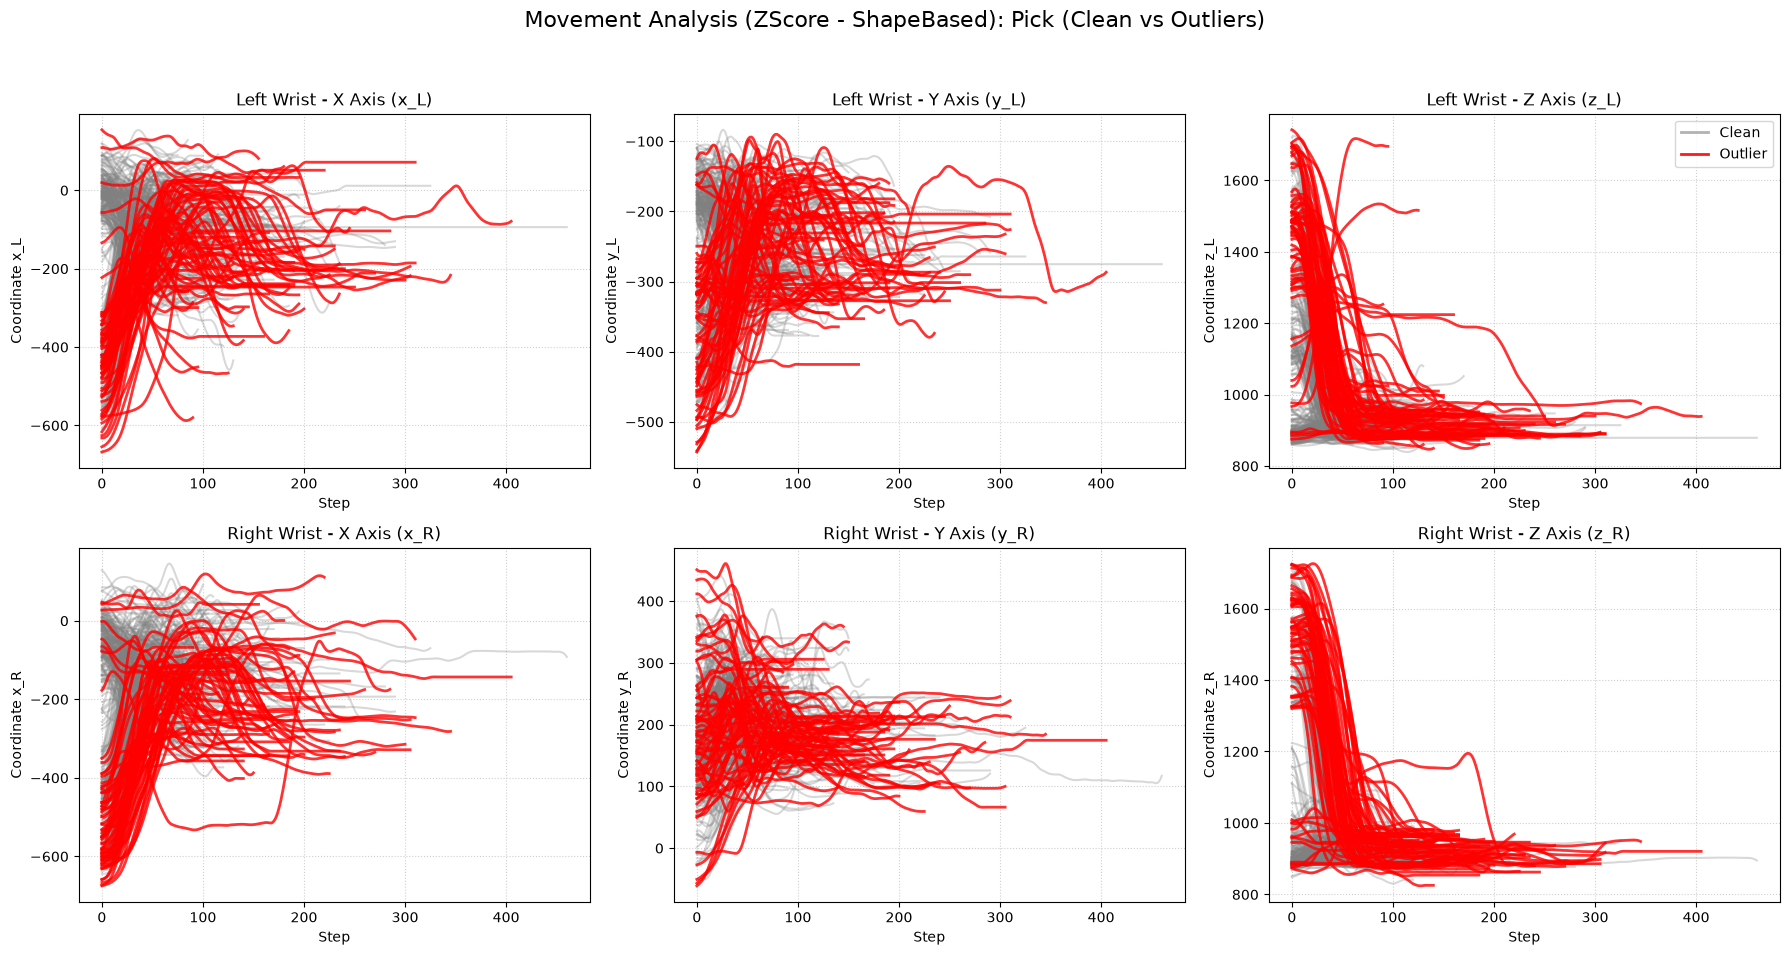

In [ ]:
# plot_movement_data(
#     clean_data=X_movement_clean,
#     outlier_data=X_movement_outliers,
#     target_movement=TARGET_MOVEMENT,
#     algorithm_name=ALGORITHM_NAME,
#     save_fig=Configs.SAVE_PLOTS,
#     save_path=Configs.DESKTOP_PATH,
#     model_representation=MODEL_REPRESENTATION
# )